DSC540-T301 <br>
Week 3&4 Assignment<br>
Jeremy Barton <br>

### The Data Wrangling Workshop: Activity 3.01, page 155

1. Load the necessary libraries

In [1]:
# Import numpy, pandas and matplotlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

2. Read in the Boston Housing dataset (given as a .csv file) from the
local directory.

In [11]:
# Use .read_csv() to read in Boston_housing.csv
housing_df = pd.read_csv("Boston_housing.csv")
# housing_df

3. Check the first 10 records. Find the total number of records.

In [12]:
# Use .head() and throw a 10 inside
housing_df.head(10)

,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,PRICE
0,0.00632,18.0,2.31,0,0.538,6.575,65.2,4.0900,1,296,15.3,396.90,4.98,24.0
1,0.02731,0.0,7.07,0,0.469,6.421,78.9,4.9671,2,242,17.8,396.90,9.14,21.6
2,0.02729,0.0,7.07,0,0.469,7.185,61.1,4.9671,2,242,17.8,392.83,4.03,34.7
3,0.03237,0.0,2.18,0,0.458,6.998,45.8,6.0622,3,222,18.7,394.63,2.94,33.4
4,0.06905,0.0,2.18,0,0.458,7.147,54.2,6.0622,3,222,18.7,396.90,5.33,36.2
5,0.02985,0.0,2.18,0,0.458,6.430,58.7,6.0622,3,222,18.7,394.12,5.21,28.7
6,0.08829,12.5,7.87,0,0.524,6.012,66.6,5.5605,5,311,15.2,395.60,12.43,22.9
7,0.14455,12.5,7.87,0,0.524,6.172,96.1,5.9505,5,311,15.2,396.90,19.15,27.1
8,0.21124,12.5,7.87,0,0.524,5.631,100.0,6.0821,5,311,15.2,386.63,29.93,16.5
9,0.17004,12.5,7.87,0,0.524,6.004,85.9,6.5921,5,311,15.2,386.71,17.10,18.9


4. Create a smaller DataFrame with columns that do not include CHAS, NOX, B,
and LSTAT:
Chas: Charlse River Dummy variable
Nox: Nitric Oxide concentration
B: Proportion of the population that is African American
LSTAT: Percentage of lower-income population

In [13]:
# Creating f_housing from housing df using .drop()
f_housing = housing_df.drop(['CHAS','NOX','B','LSTAT'], axis=1)
f_housing.head(3)

,CRIM,ZN,INDUS,RM,AGE,DIS,RAD,TAX,PTRATIO,PRICE
0,0.00632,18.0,2.31,6.575,65.2,4.0900,1,296,15.3,24.0
1,0.02731,0.0,7.07,6.421,78.9,4.9671,2,242,17.8,21.6
2,0.02729,0.0,7.07,7.185,61.1,4.9671,2,242,17.8,34.7


5. Check the last seven records of the new DataFrame you just created.

In [14]:
# Use .tail() to find the last seven records
f_housing.tail(7)

,CRIM,ZN,INDUS,RM,AGE,DIS,RAD,TAX,PTRATIO,PRICE
499,0.17783,0.0,9.69,5.569,73.5,2.3999,6,391,19.2,17.5
500,0.22438,0.0,9.69,6.027,79.7,2.4982,6,391,19.2,16.8
501,0.06263,0.0,11.93,6.593,69.1,2.4786,1,273,21.0,22.4
502,0.04527,0.0,11.93,6.120,76.7,2.2875,1,273,21.0,20.6
503,0.06076,0.0,11.93,6.976,91.0,2.1675,1,273,21.0,23.9
504,0.10959,0.0,11.93,6.794,89.3,2.3889,1,273,21.0,22.0
505,0.04741,0.0,11.93,6.030,80.8,2.5050,1,273,21.0,11.9


6. Plot the histograms of all the variables (columns) in the new DataFrame.

<Axes: >

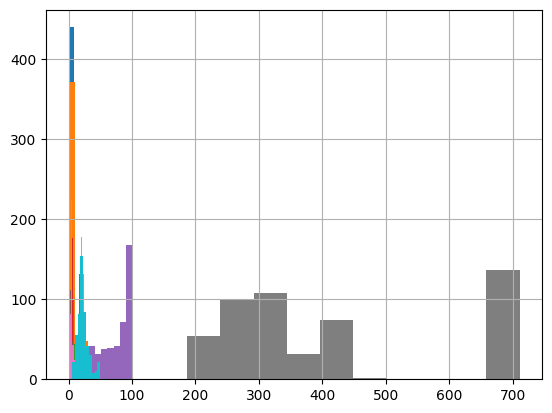

In [15]:
f_housing['CRIM'].hist()
f_housing['ZN'].hist()
f_housing['INDUS'].hist()
f_housing['RM'].hist()
f_housing['AGE'].hist()
f_housing['DIS'].hist()
f_housing['RAD'].hist()
f_housing['TAX'].hist()
f_housing['PTRATIO'].hist()
f_housing['PRICE'].hist()

7. Plot them all at once using a for loop. Try to add a unique title to the plot.

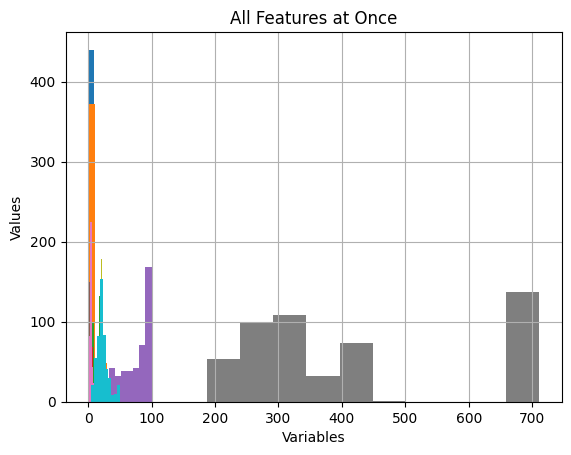

In [16]:
# For each column in f_housing...
for col in f_housing.columns:
    # Create histogram from each variable
    f_housing[col].hist(bins=10)
    plt.title("All Features at Once")
    plt.xlabel("Variables")
    plt.ylabel("Values")


8. Create a scatter plot of crime rate versus price.

<Axes: xlabel='CRIM', ylabel='PRICE'>

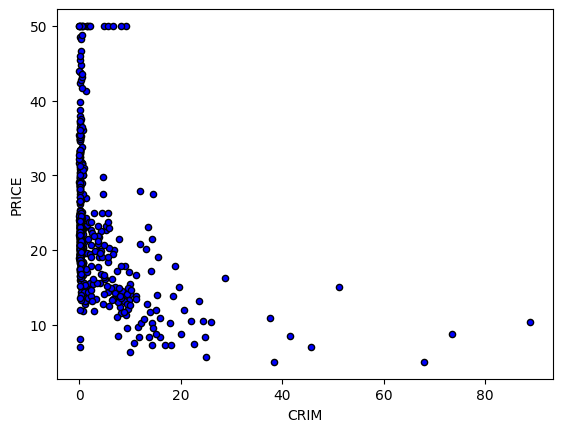

In [17]:
# Using .scatter() on the two variables
f_housing.plot.scatter('CRIM', 'PRICE', c='blue', edgecolor='k')

9. Plot log10(crime) versus price.

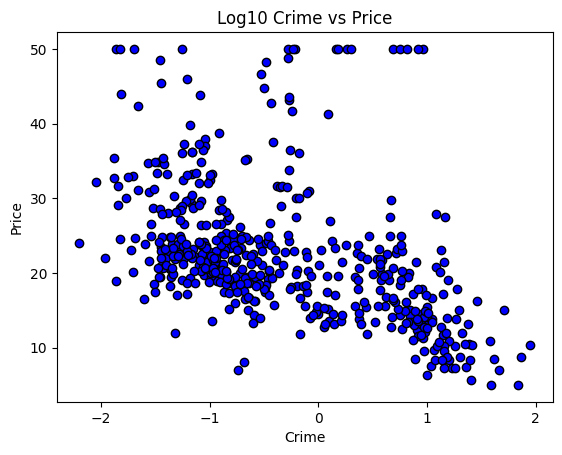

In [18]:
# Using scatter() on fhousing

# *** NOTE TO SELF ***
# REMINDER: 
# Always use f_housing['CRIM'] to access a column.
# f_housing('CRIM') is wrong — DataFrames are not callable.

plt.scatter(
    np.log10(f_housing['CRIM']), # log10() used on 'CRIM'
    f_housing['PRICE'],
    c='blue',
    edgecolor='k'
)

# Create title and axis labels
plt.xlabel('Crime')
plt.ylabel('Price')
plt.title('Log10 Crime vs Price')
plt.show()


10. Calculate some useful statistics, such as mean rooms per dwelling, median
age, mean distances to five Boston employment centers, and the percentage of
houses with a low price (< $20,000).

In [10]:
# Rooms per dwelling
RPD = f_housing['RM'].mean() # Using .mean() on RM from f_housing

# Median Age
MEDAGE = f_housing['AGE'].median() # Using .median() on AGE from f_housing 

# Housing under 20K
LESS20K = f_housing['PRICE'] < 20

# Median distance from five Boston employment centers
MEDIS = f_housing['DIS'].mean()
print(f'Rooms Per Dwelling: {RPD}')
print(f'Median age: {MEDAGE}')
print(f'Median Distance: {MEDIS}')
print(f'Homes less than 20K: {LESS20K}')


Rooms Per Dwelling: 6.284634387351779
Median age: 77.5
Median Distance: 3.795042687747036
Homes less than 20K: 0      False
1      False
2      False
3      False
4      False
       ...  
501    False
502    False
503    False
504    False
505     True
Name: PRICE, Length: 506, dtype: bool


As the output shows, there are no homes under 20K.

Bellevue University 2025 | Jeremy Barton